In [1]:
# needed
import os
import re
import soundfile as sf
from IPython.display import Audio
from IPython.display import display
import numpy as np
# recommended ...
from scipy import signal
from scipy.signal import stft
from scipy.signal import spectrogram
from scipy.signal import fftconvolve
from scipy.io import wavfile
from scipy.fft import fft, ifft, fftfreq
import scipy.io
import matplotlib.pyplot as plt


In [2]:
#uncomment before run (osobne sem si manualne stahoval muj set songu - proto nepouzivam)
'''
# read data
login = "239151"
zip_file = "known" + ".zip"
for name in ("known.zip", "valid.zip", login + ".zip"):
  file = "https://www.fit.vut.cz/study/course/ISS/public/proj2025-26/" + name
  !rm $name
  !wget $file
  !unzip -o -q $name
'''

'\n# read data\nlogin = "239151"\nzip_file = "known" + ".zip"\nfor name in ("known.zip", "valid.zip", login + ".zip"):\n  file = "https://www.fit.vut.cz/study/course/ISS/public/proj2025-26/" + name\n  !rm $name\n  !wget $file\n  !unzip -o -q $name\n'

In [3]:
# load the known data - the function returns a big matrix with all the signals
def load_data (S, dirname, count, no_samples):
  ii = 0
  for one in np.arange(count):
    S[ii], Fs = sf.read(dirname + "/" + str(one) + ".wav")
    ii = ii+1

Fs = 16000
# load known data
N_known = 706; duration_known = 10; no_samples_known = Fs * duration_known
known_signals=np.zeros([N_known, no_samples_known]); load_data(known_signals, "known", N_known, no_samples_known)
# load validation data
N_valid = 50; duration_valid = 5; no_samples_valid = Fs * duration_valid
valid_signals=np.zeros([N_valid, no_samples_valid]); load_data(valid_signals, "valid", N_valid, no_samples_valid)

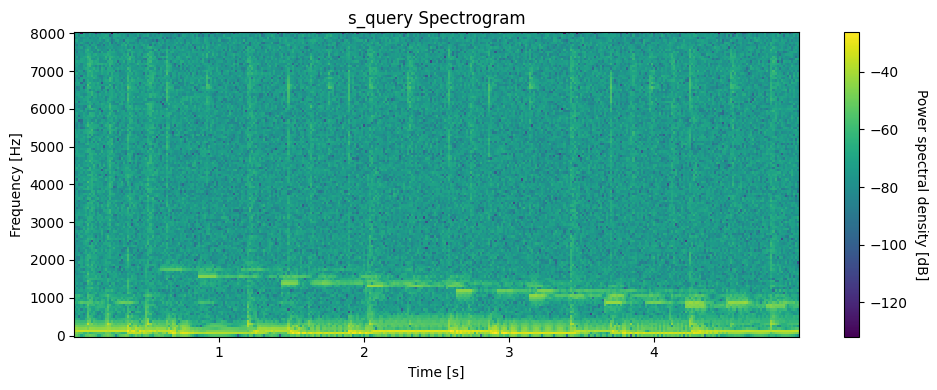

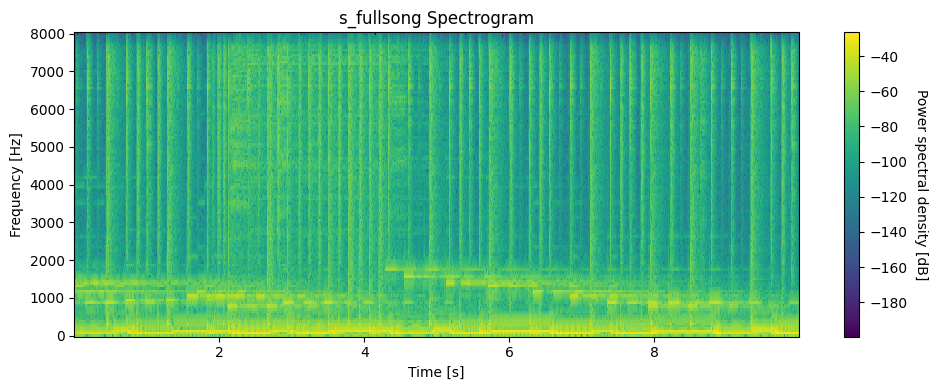

In [4]:
#vizualizace
def spectrogram_borrowed(s, Fs, title="Spectrogram"):
    f, t, sgr = spectrogram(s, Fs)
    sgr_log = 10 * np.log10(sgr+1e-20)

    plt.figure(figsize=(10,4))
    plt.pcolormesh(t,f,sgr_log)
    plt.gca().set_xlabel('Time [s]')
    plt.gca().set_ylabel('Frequency [Hz]')
    plt.title(title)
    cbar = plt.colorbar()
    cbar.set_label('Power spectral density [dB]', rotation=270, labelpad=15)
    plt.tight_layout()

def fft_borrowed(s):
    N = len(s)
    X = np.fft.fft(s)
    kall = np.arange(0,N)
    Xmag = np.abs(X)

    plt.figure(figsize=(10,4))
    plt.plot(kall,Xmag)
    plt.gca().set_xlabel('$|X[k]|$')

#example
s_valid = valid_signals[0]
s_known = known_signals[182]

spectrogram_borrowed(s_valid, Fs, 's_query Spectrogram')
#fft_borrowed(s_valid)
display(Audio(s_valid, rate=Fs))
spectrogram_borrowed(s_known, Fs, 's_fullsong Spectrogram')
#fft_borrowed(s_known)
display(Audio(s_known, rate=Fs))

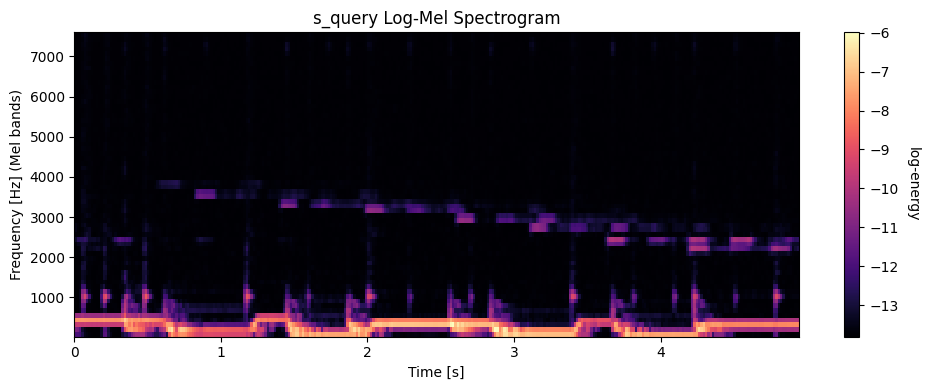

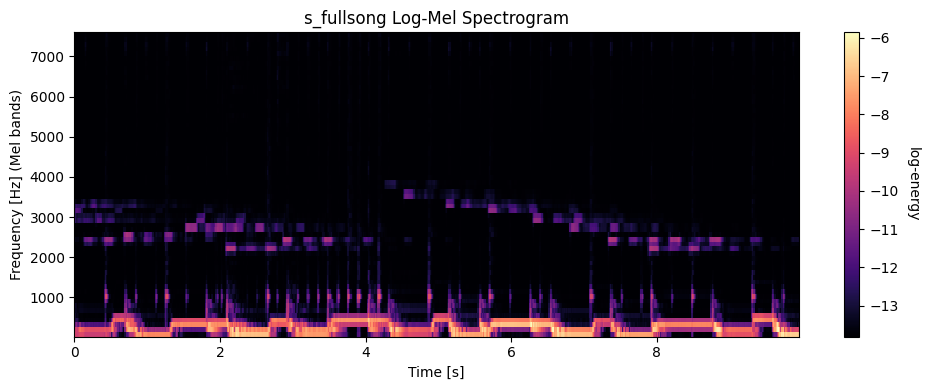

In [5]:
#log-Mel spektrogram podle:
#https://apxml.com/courses/applied-speech-recognition/chapter-2-feature-extraction-for-speech/filter-banks-log-mel-spectrograms

#unlimited poweeeeeer (vraci power spectrogram)
def power_spectrogram_from_signal(x, Ts, n_fft, hop):
    f, t, Z = stft(x, Ts, nperseg=n_fft, noverlap=n_fft - hop, padded=False, boundary=None) #short-term ft -> 1 krok viz zdroj
    S = (np.abs(Z) ** 2).astype(np.float32) #unlimited poweeeeeeer -> 2 krok viz zdroj
    return S

#Mel filterbank -> 2,5 krok viz zdroj
def mel_filterbank(Ts, n_fft, n_mels, fmin, fmax):
    if fmax is None:
        fmax = Ts / 2   #dobrej stred
    def hz_to_mel(f): return 2595.0 * np.log10(1.0 + f / 700.0) #mel scale
    def mel_to_hz(m): return 700.0 * (10.0**(m / 2595.0) - 1.0) #uno reverse

    m_pts = np.linspace(hz_to_mel(fmin), hz_to_mel(fmax), n_mels + 2)   #na mely
    hz_pts = mel_to_hz(m_pts)                                           #stejnej array ale v hz
    freqs = np.fft.rfftfreq(n_fft, 1.0 / Ts)                            #baaazosky fftcka

    fb = np.zeros((n_mels, len(freqs)), dtype=np.float32)               #prep mat filterbanku
    bin_idxs = np.searchsorted(freqs, hz_pts).clip(0, len(freqs) - 1)   #indexy breakpointu v FFT binech

    #vyplneni trojuhelnikovych filtru filterbanku - koukni na obrazek ve zdroji/protokolu
    for m in range(1, n_mels + 1):
        l, c, r = bin_idxs[m-1], bin_idxs[m], bin_idxs[m+1]
        if c > l:
            fb[m-1, l:c] = (freqs[l:c] - freqs[l]) / (freqs[c] - freqs[l] + 1e-12)
        if r > c:
            fb[m-1, c:r] = (freqs[r] - freqs[c:r]) / (freqs[r] - freqs[c] + 1e-12)

    # Slaney-style normalizace plochy trojuhelniku (neni nutna)
    hz_bw = (hz_pts[2:] - hz_pts[:-2])      #rozsah pro kazdy mel band
    scale = 2.0 / np.maximum(hz_bw, 1e-12)  #uprava vrchu trojuhelniku
    fb *= scale[:, None].astype(np.float32) #final uprava trojuhelniku -> plochy se vsude rovnaji 1
    return fb

#fullko - master funkce: signal -> log-Mel spectrogram
def logmel_from_signal(x, Ts, n_fft, hop, n_mels, fmin, fmax, eps, rms_target):
    #nejprv normalizuji rms na rms_target - pomuze pozdeji pri korelaci
    if rms_target is not None:
        rms = np.sqrt(np.mean(x**2) + 1e-12)
        if rms > 0:
            x = x * (rms_target / rms)

    #nabihame na log-Mel
    S = power_spectrogram_from_signal(x, Ts, n_fft, hop)  #unlimited poweeeeer -> 2 krok viz zdroj
    FB = mel_filterbank(Ts, n_fft, n_mels, fmin, fmax)    #Mel filterbank -> 2,5 krok viz zdroj
    M = np.dot(FB, S)                                     #Mel spectrogram-> 3 krok viz zdroj
    logM = np.log(M + eps).astype(np.float32)             #log-Mel spectrogram-> 4 (posledni) krok viz zdroj
    return logM

#vizualizace
def plot_logmel_pcolormesh(logM, Ts=16000, hop=256, fmin=20.0, fmax=7600.0, title="Log-Mel Spectrogram"):
    n_mels, T = logM.shape
    t = np.arange(T + 1) * (hop / Ts)
    f = np.linspace(fmin, fmax, n_mels + 1)

    plt.figure(figsize=(10, 4))
    plt.pcolormesh(t, f, logM, shading='auto', cmap='magma')
    plt.gca().set_xlabel("Time [s]")
    plt.gca().set_ylabel("Frequency [Hz] (Mel bands)")
    plt.title(title)
    cbar = plt.colorbar()
    cbar.set_label("log-energy", rotation=270, labelpad=15)
    plt.tight_layout()
    plt.show()

#example
Ts = 16000
n_fft = 1024    #lepsi rezoluce misto defaultni 256 - lepsi detail spektra
hop = 256       #opet lepsi rezoluce misto defaultni n_fft//2 - zvysuje pocet framu na song
n_mels = 64     #urcuje kvalitu prevodu na mel spectrogram
eps=1e-6        #vyhyba se log(0) - doporuceno v librose
rms_target=0.2  #doporucenej target
fmin, fmax = 20.0, 7600.0   #viz doporuceni od Honzy - killnout vysoke a nizke f

s_valid_logmel = logmel_from_signal(s_valid, Ts, n_fft, hop, n_mels, fmin, fmax, eps, rms_target)
plot_logmel_pcolormesh(s_valid_logmel, Ts, hop, fmin, fmax, 's_query Log-Mel Spectrogram')
s_known_logmel = logmel_from_signal(s_known, Ts, n_fft, hop, n_mels, fmin, fmax, eps, rms_target)
plot_logmel_pcolormesh(s_known_logmel, Ts, hop, fmin, fmax, 's_fullsong Log-Mel Spectrogram')


In [6]:
def ncc(S_song, S_query, eps):
    #funkce pocita cross-correlaci mezi songou a posunijicim se hledanym utrzkem
    #pro definici NCC see protokol

    F, L = S_query.shape   #dim

    Q_mean = S_query.mean()             #stred
    Qc = S_query - Q_mean               #centrovani na mean 0
    Qnorm = np.linalg.norm(Qc) + eps    #normovani + eps, aby sme nepracovali s nulama

    #tady se bude dit ta magie
    #zneuziju funkce fftconvolve, tak ze flipnu convolucni okno Qc[::-1, ::-1]
    #voa-la -> mam z toho corelaci
    C = fftconvolve(S_song, Qc[::-1, ::-1], mode='valid').reshape(-1)

    #tady to tak lehky nebude, chcem Pnorm pro kazdy posun
    J = np.ones((F, L), dtype=S_song.dtype)                                     #init matice
    S_t  = fftconvolve(S_song,   J[::-1, ::-1], mode='valid').reshape(-1)       #P_t, recyklujem magii z C
    S_t2 = fftconvolve(S_song**2, J[::-1, ::-1], mode='valid').reshape(-1)      #P_t^2, recyklujem magii z C
    V  = np.maximum(S_t2 - (S_t**2)/(F*L), 0.0)                                 #variance

    numer = C                           #<P_t, Qc> ,ale jelikoz mame Q centrovany, tak staci jen C
    denom = np.sqrt(V) * Qnorm + eps    #||P_t - mean(P_t)|| * ||Q - mean(Q)||
    ncc_scores = numer / denom          #matice skorecek

    score = float(ncc_scores[np.argmax(ncc_scores)])    #cucam nejlepsi skore
    return score

#example
score = ncc(s_known_logmel, s_valid_logmel, 1e-8)
print(score)

0.9992415904998779


In [7]:
def compute_similarity_matrix(querry_signals, known_signals, N_query, N_known,Ts,n_fft,hop,n_mels,eps,rms_target,fmin,fmax):
    similarities = np.zeros((N_query, N_known))
    querry_spectrograms = [None] * N_query
    known_spectrograms = [None] * N_known
    for i in range(N_query):
        querry_spectrograms[i] = logmel_from_signal(querry_signals[i],Ts, n_fft, hop, n_mels, fmin, fmax, eps, rms_target)
    for i in range(N_known):
        known_spectrograms[i] = logmel_from_signal(known_signals[i],Ts, n_fft, hop, n_mels, fmin, fmax, eps, rms_target)
    print('spectrograms done')
    for i in range(N_query):
        for j in range(N_known):
            similarities[i,j] = ncc(known_spectrograms[j], querry_spectrograms[i], 1e-8)
            print(i,j)
            print('podobnost:',similarities[i,j])
    return similarities

In [8]:
# evaluation - the function produces Top-1 and Top-5 accuracy on validation data
def eval(scores, key):
  indices = np.flip(np.argsort(scores), axis=-1) # we want highest to lowest ...
  #print(scores[0,key[0]], key[0], indices)
  top1acc = np.sum(key == indices[:,0]) / indices.shape[0]
  top5acc = 0
  for ii in range(5):
    top5acc += np.sum(key == indices[:,ii])
  top5acc /=  indices.shape[0]
  return top1acc, top5acc

key = np.loadtxt("valid/key.txt", delimiter = ',', usecols=(1), dtype ='int')

In [12]:
# here comes the computation and evaluation on validation data ...
Ts = 16000
n_fft = 512 #1024
hop = 256
n_mels = 64
eps=1e-6
rms_target=0.2
fmin, fmax = 20.0, 7600.0

scores_matrix = compute_similarity_matrix(valid_signals, known_signals, N_valid, N_known,Ts,n_fft,hop,n_mels,eps,rms_target,fmin,fmax)

top1, top5 = eval(scores_matrix, key)
print("Top 1 accuracy ", top1 * 100, "%, Top 5 accuracy ", top5 * 100, "%" )

spectrograms done
0 0
podobnost: 0.0841907411813736
0 1
podobnost: 0.1977747231721878
0 2
podobnost: 0.39543285965919495
0 3
podobnost: 0.6797289848327637
0 4
podobnost: 0.007778472267091274
0 5
podobnost: 0.4996277391910553
0 6
podobnost: 0.5617257356643677
0 7
podobnost: 0.5538676381111145
0 8
podobnost: 0.6130407452583313
0 9
podobnost: 0.559867262840271
0 10
podobnost: 0.033246614038944244
0 11
podobnost: 0.3819445073604584
0 12
podobnost: 0.16720494627952576
0 13
podobnost: 0.4899619221687317
0 14
podobnost: 0.5625067353248596
0 15
podobnost: 0.6026478409767151
0 16
podobnost: 0.5978292226791382
0 17
podobnost: 0.546730637550354
0 18
podobnost: 0.24822841584682465
0 19
podobnost: 0.5881048440933228
0 20
podobnost: 0.3882178068161011
0 21
podobnost: 0.5676969289779663
0 22
podobnost: 0.43173879384994507
0 23
podobnost: 0.3792179226875305
0 24
podobnost: 0.7182822227478027
0 25
podobnost: 0.5062469840049744
0 26
podobnost: 0.11328653246164322
0 27
podobnost: 0.3805415630340576
0 28


In [13]:
# NOW on YOUR DATA ! Your task is to produce a matrix 50 x 706 with similarity measures

# load your data
N_eval = 50; duration_eval = 5; no_samples_eval = Fs * duration_eval; login = "239151"
eval_signals=np.zeros([N_eval, no_samples_eval]); load_data(eval_signals, login, N_eval, no_samples_eval)

# YOUR CODE COMES HERE ! Your task is to produce a matrix 50 x 706 with similarity measures
Ts = 16000
n_fft = 512
hop = 256
n_mels = 64
eps=1e-6
rms_target=0.2
fmin, fmax = 20.0, 7600.0

scores_matrix = compute_similarity_matrix(eval_signals, known_signals, N_valid, N_known,Ts,n_fft,hop,n_mels,eps,rms_target,fmin,fmax)

# export it
np.savetxt("eval.txt", scores_matrix)

spectrograms done
0 0
podobnost: 0.5030912756919861
0 1
podobnost: 0.6108582615852356
0 2
podobnost: 0.5736397504806519
0 3
podobnost: 0.4082954227924347
0 4
podobnost: 0.49239280819892883
0 5
podobnost: 0.650292694568634
0 6
podobnost: 0.509608805179596
0 7
podobnost: 0.6771990656852722
0 8
podobnost: 0.3861079812049866
0 9
podobnost: 0.6090212464332581
0 10
podobnost: 0.358936607837677
0 11
podobnost: 0.5919698476791382
0 12
podobnost: 0.6456645131111145
0 13
podobnost: 0.6110700964927673
0 14
podobnost: 0.6033119559288025
0 15
podobnost: 0.6095079779624939
0 16
podobnost: 0.6454614996910095
0 17
podobnost: 0.2905966341495514
0 18
podobnost: 0.5190250277519226
0 19
podobnost: 0.4490882158279419
0 20
podobnost: 0.6684196591377258
0 21
podobnost: 0.5795380473136902
0 22
podobnost: 0.6973978281021118
0 23
podobnost: 0.6610329151153564
0 24
podobnost: 0.533841609954834
0 25
podobnost: 0.5316494107246399
0 26
podobnost: 0.6048718094825745
0 27
podobnost: 0.582626461982727
0 28
podobnost: 

In [14]:
def my_eval(scores):
  indices = np.flip(np.argsort(scores), axis=-1)
  N, A = indices.shape
  for i in range(N):
    print('my song:',i,'should match:',indices[i,0])

my_eval(scores_matrix)

s_mine = eval_signals[0]
s_known = known_signals[579]
display(Audio(s_mine, rate=Fs))
display(Audio(s_known, rate=Fs))

my song: 0 should match: 579
my song: 1 should match: 172
my song: 2 should match: 271
my song: 3 should match: 585
my song: 4 should match: 575
my song: 5 should match: 317
my song: 6 should match: 689
my song: 7 should match: 130
my song: 8 should match: 426
my song: 9 should match: 648
my song: 10 should match: 691
my song: 11 should match: 26
my song: 12 should match: 505
my song: 13 should match: 351
my song: 14 should match: 549
my song: 15 should match: 262
my song: 16 should match: 499
my song: 17 should match: 702
my song: 18 should match: 195
my song: 19 should match: 599
my song: 20 should match: 624
my song: 21 should match: 183
my song: 22 should match: 184
my song: 23 should match: 84
my song: 24 should match: 3
my song: 25 should match: 249
my song: 26 should match: 189
my song: 27 should match: 114
my song: 28 should match: 645
my song: 29 should match: 280
my song: 30 should match: 663
my song: 31 should match: 647
my song: 32 should match: 21
my song: 33 should match: